# PathSnap — 03 Model Comparison (6 algorithms)
Results produced by `python -m src.models.train_compare` (re-run it to reproduce; ~6 min). This notebook only loads and presents the saved results.

**Protocol (identical for every model):** binary task *is this candidate the true arc?* · 5-fold GroupKFold with trip as the group on the 80 train trips · refit on all train rows · evaluate on all 18,426 cleaned GPS points of the 10 student-test trips (a point whose true arc is not among its candidates counts as wrong) · seed 42.

**Accuracy = observation-level Top-1 accuracy:** for each GPS point take the candidate with the highest predicted probability; correct if it is the point's true arc (definition from the Models & Training guidelines).

In [1]:
import sys, os; sys.path.insert(0, os.path.abspath('..'))
import pandas as pd, json
from IPython.display import Image, display
d = pd.read_csv('../experiments/model_comparison.csv')
t = d[['model','family','config','cv_macro_f1_mean','cv_macro_f1_std','st_top1_acc','st_macro_f1','st_precision_pos','st_recall_pos','st_log_loss','st_route_continuity','train_s','st_infer_ms_per_1k_rows']]
t.columns = ['Model','Family','Config','CV macro F1','CV std','Accuracy (Top-1)','Test macro F1','Precision (true arc)','Recall (true arc)','Log loss','Route continuity','Train time (s)','Inference ms/1k rows']
t.sort_values('CV macro F1', ascending=False).round(4)

,Model,Family,Config,CV macro F1,CV std,Accuracy (Top-1),Test macro F1,Precision (true arc),Recall (true arc),Log loss,Route continuity,Train time (s),Inference ms/1k rows
5,mlp,Neural network,"64-32 ReLU, Adam, early stop",0.8921,0.0128,0.8485,0.9048,0.8650,0.8181,0.1291,0.9167,14.0303,0.3792
2,knn,Instance-based,"k=25, distance-weighted",0.8874,0.0129,0.8425,0.9036,0.8532,0.8259,0.1822,0.9138,0.1524,22.8594
3,rf,Ensemble (bagging),"200 trees, depth 14",0.8803,0.0154,0.8496,0.8844,0.7166,0.9420,0.1724,0.9159,17.9755,2.7048
4,lgbm,Boosting,"300 trees, lr 0.05, 31 leaves",0.8772,0.0157,0.8555,0.8791,0.7012,0.9482,0.1769,0.9200,2.4334,2.7660
0,logreg,Linear,"L2, C=1, balanced",0.8365,0.0098,0.8398,0.8440,0.6352,0.9232,0.2438,0.9109,0.1712,0.0467
1,gnb,Probabilistic,default var_smoothing,0.8281,0.0099,0.8317,0.8231,0.6056,0.8873,0.4866,0.8956,0.1091,0.1987


## Per-fold cross-validation scores (stability)

In [2]:
folds = pd.DataFrame({m: json.load(open(f'../experiments/logs/{m}.json'))['cv_folds'] for m in d.model}, index=[f'fold {i}' for i in range(5)]).T
folds.round(4)

,fold 0,fold 1,fold 2,fold 3,fold 4
logreg,0.8298,0.8444,0.8373,0.8490,0.8220
gnb,0.8221,0.8423,0.8377,0.8200,0.8183
knn,0.8828,0.8963,0.8847,0.9057,0.8676
rf,0.8659,0.8976,0.8782,0.8983,0.8617
lgbm,0.8623,0.8955,0.8736,0.8954,0.8590
mlp,0.8877,0.9011,0.8919,0.9087,0.8711


## Comparison plots

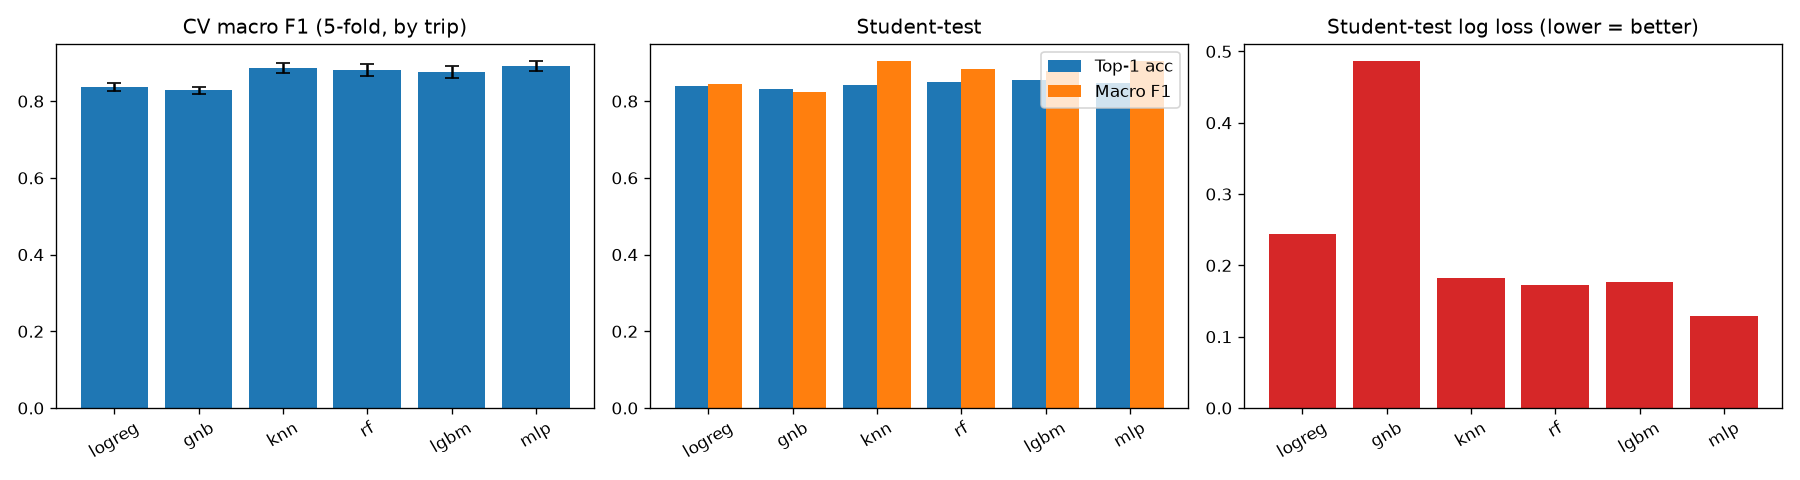

In [3]:
display(Image('../reports/figures/model_comparison.png'))

## Confusion matrices (student-test, candidate level, threshold 0.5)

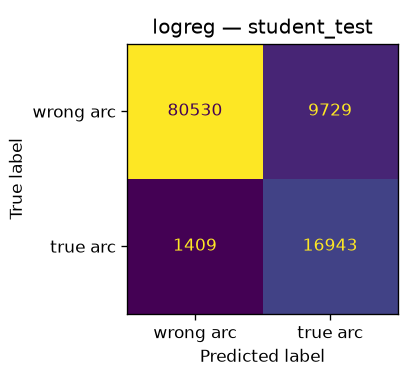

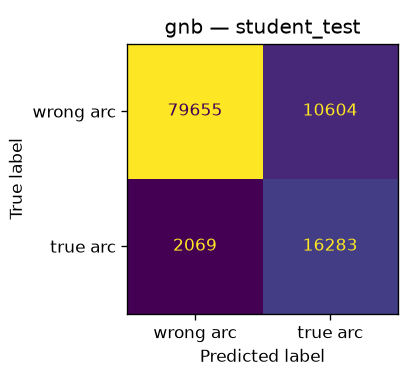

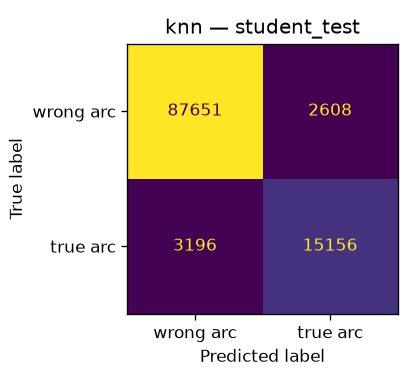

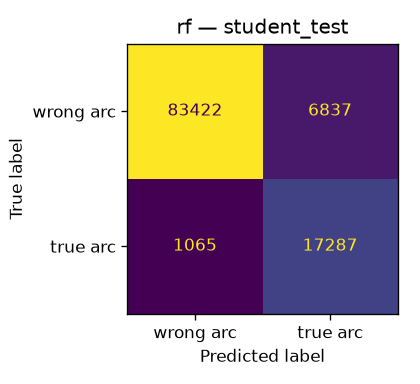

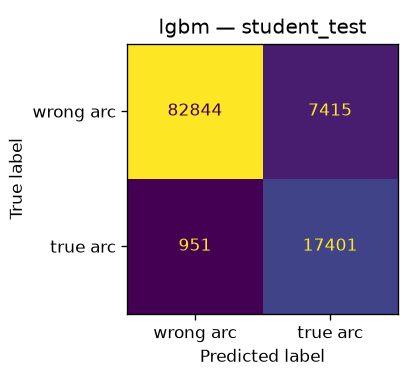

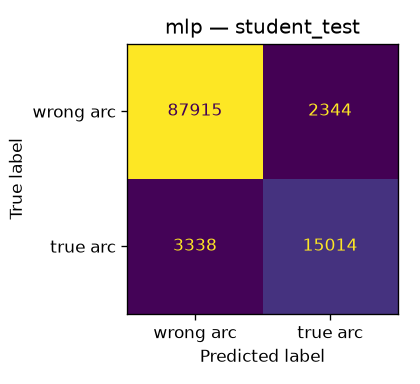

In [4]:
for m in d.model: display(Image(f'../reports/figures/cm_{m}.png', width=300))

## MLP training history (the only model with epoch-wise training)

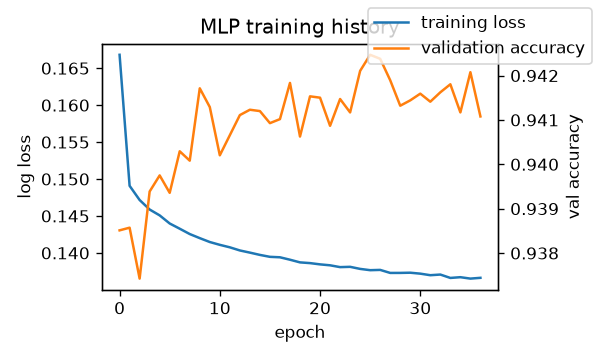

In [5]:
display(Image('../reports/figures/mlp_history.png'))

## Selection
- **MLP** has the best CV macro F1 (primary metric — classes are imbalanced, 17.6% positives) and the lowest log loss (best-calibrated probabilities, which the HMM uses as emission probabilities).
- **LightGBM** has the highest Top-1 accuracy, but only by ~0.7 points; RF/LightGBM/MLP are within 1 point on accuracy.
- **KNN** is competitive on F1 but ~60× slower at inference than the MLP — impractical for the API on large road networks.
- **LogReg / GaussianNB** underfit: they cannot model feature interactions such as heading × speed.
- No model overfits strongly: CV and student-test macro F1 are close for all six.